In [2]:
import h2o
from h2o.estimators import H2OGradientBoostingEstimator, H2ORandomForestEstimator
import numpy as np
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split

In [5]:
h2o.init()

Checking whether there is an H2O instance running at http://localhost:54321..... not found.
Attempting to start a local H2O server...
; Java HotSpot(TM) 64-Bit Server VM (build 25.441-b07, mixed mode)
  Starting server from C:\Users\House\AppData\Local\Programs\Python\Python310\Lib\site-packages\h2o\backend\bin\h2o.jar
  Ice root: C:\Users\House\AppData\Local\Temp\tmpvjg9cd5c
  JVM stdout: C:\Users\House\AppData\Local\Temp\tmpvjg9cd5c\h2o_House_started_from_python.out
  JVM stderr: C:\Users\House\AppData\Local\Temp\tmpvjg9cd5c\h2o_House_started_from_python.err
  Server is running at http://127.0.0.1:54321
Connecting to H2O server at http://127.0.0.1:54321 ... successful.


H2O_cluster_uptime:,02 secs
H2O_cluster_timezone:,Europe/Berlin
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.46.0.7
H2O_cluster_version_age:,"14 days, 2 hours and 16 minutes"
H2O_cluster_name:,H2O_from_python_House_ufz12t
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,7.013 Gb
H2O_cluster_total_cores:,32
H2O_cluster_allowed_cores:,32
H2O_cluster_status:,"locked, healthy"


In [6]:
pd.set_option('display.max_columns', 500)
pd.set_option('display.max_rows', 500)

In [ ]:
pdf = pd.read_csv("C:/Users/House/OneDrive/Documents/Sohan_Arun/Career/Projects/Deep Learning/Licence Classifier/License_Data.csv")
print(pdf.shape)


(85895, 32)
                 ID  LICENSE_ID  ACCOUNT_NUMBER  SITE_NUMBER  \
0    35342-20020816     1256593           32811            1   
1  1358463-20051116     1639294          262311           29   
2  1980233-20090722     1980233          345008            1   
3  1476582-20040211     1476582          273121            1   
4  1141408-20080516     1896750          213785            1   

                     LEGAL_NAME        DOING_BUSINESS_AS_NAME  \
0                  CARMEN CAHUE         CLAUDIA'S BRIDAL SHOP   
1           ISLA TROPICAL, INC.                 ISLA TROPICAL   
2                DJS REMODELING          DJS REMODELING, INC.   
3      ALL-BRY CONSTRUCTION CO.      ALL-BRY CONSTRUCTION CO.   
4  MCDONOUGH MECHANICAL SERVICE  MCDONOUGH MECHANICAL SERVICE   

                      ADDRESS      CITY STATE ZIP_CODE  WARD  PRECINCT  \
0  2625 S CENTRAL PARK AVE  1   CHICAGO    IL  60623.0  22.0      28.0   
1         2825 W MONTROSE AVE   CHICAGO    IL    60618  33.0    

C:\Users\House\AppData\Local\Temp\ipykernel_20896\528842546.py:1: DtypeWarning: Columns (9) have mixed types. Specify dtype option on import or set low_memory=False.
  pdf = pd.read_csv("C:/Users/House/OneDrive/Documents/Sohan_Arun/Career/Projects/Deep Learning/Licence Classifier/License_Data.csv")


In [18]:
print(pdf.head())

                 ID  LICENSE_ID  ACCOUNT_NUMBER  SITE_NUMBER  \
0    35342-20020816     1256593           32811            1   
1  1358463-20051116     1639294          262311           29   
2  1980233-20090722     1980233          345008            1   
3  1476582-20040211     1476582          273121            1   
4  1141408-20080516     1896750          213785            1   

                     LEGAL_NAME        DOING_BUSINESS_AS_NAME  \
0                  CARMEN CAHUE         CLAUDIA'S BRIDAL SHOP   
1           ISLA TROPICAL, INC.                 ISLA TROPICAL   
2                DJS REMODELING          DJS REMODELING, INC.   
3      ALL-BRY CONSTRUCTION CO.      ALL-BRY CONSTRUCTION CO.   
4  MCDONOUGH MECHANICAL SERVICE  MCDONOUGH MECHANICAL SERVICE   

                      ADDRESS      CITY STATE ZIP_CODE  WARD  PRECINCT  \
0  2625 S CENTRAL PARK AVE  1   CHICAGO    IL  60623.0  22.0      28.0   
1         2825 W MONTROSE AVE   CHICAGO    IL    60618  33.0      23.0   
2 

In [19]:
print("Columns:", pdf.columns.tolist())

Columns: ['ID', 'LICENSE_ID', 'ACCOUNT_NUMBER', 'SITE_NUMBER', 'LEGAL_NAME', 'DOING_BUSINESS_AS_NAME', 'ADDRESS', 'CITY', 'STATE', 'ZIP_CODE', 'WARD', 'PRECINCT', 'WARD_PRECINCT', 'POLICE_DISTRICT', 'LICENSE_CODE', 'LICENSE_DESCRIPTION', 'LICENSE_NUMBER', 'APPLICATION_TYPE', 'APPLICATION_CREATED_DATE', 'APPLICATION_REQUIREMENTS_COMPLETE', 'PAYMENT_DATE', 'CONDITIONAL_APPROVAL', 'LICENSE_TERM_START_DATE', 'LICENSE_TERM_EXPIRATION_DATE', 'LICENSE_APPROVED_FOR_ISSUANCE', 'DATE_ISSUED', 'LICENSE_STATUS_CHANGE_DATE', 'SSA', 'LATITUDE', 'LONGITUDE', 'LOCATION', 'LICENSE_STATUS']


In [20]:
print(pdf.describe())

         LICENSE_ID  ACCOUNT_NUMBER   SITE_NUMBER          WARD      PRECINCT  \
count  8.589500e+04    85895.000000  85895.000000  36194.000000  29194.000000   
mean   1.751303e+06   196695.421701      2.556028     28.528927     54.632973   
std    3.358780e+05   126819.343760      8.655706     13.921710    163.174955   
min    3.079300e+04       10.000000      1.000000      1.000000      1.000000   
25%    1.469024e+06    54615.000000      1.000000     17.000000     12.000000   
50%    1.778754e+06   248313.000000      1.000000     30.000000     26.000000   
75%    2.067578e+06   300243.500000      2.000000     42.000000     41.000000   
max    2.456551e+06   397444.000000    417.000000     50.000000    999.000000   

       POLICE_DISTRICT  LICENSE_CODE  LICENSE_NUMBER          SSA  \
count     31883.000000  85895.000000    8.589400e+04  9449.000000   
mean         13.529812   1111.736620    1.228151e+06    29.152080   
std           7.275874    250.020872    7.431487e+05    17.4198

In [ ]:
pdf.LICENSE_STATUS.value_counts()

LICENSE_STATUS
AAI    55400
AAC    30200
REV      290
REA        3
INQ        2
Name: count, dtype: int64

In [24]:
pdf = pdf[pdf.LICENSE_STATUS.isin(['AAI', 'AAC', 'REV'])]

In [26]:
pdf.LICENSE_STATUS.value_counts()

LICENSE_STATUS
AAI    55400
AAC    30200
REV      290
Name: count, dtype: int64

In [27]:
pdf.isna().sum()

ID                                       0
LICENSE_ID                               0
ACCOUNT_NUMBER                           0
SITE_NUMBER                              0
LEGAL_NAME                               0
DOING_BUSINESS_AS_NAME                   1
ADDRESS                                  0
CITY                                     0
STATE                                    0
ZIP_CODE                                31
WARD                                 49699
PRECINCT                             56699
WARD_PRECINCT                        49698
POLICE_DISTRICT                      54010
LICENSE_CODE                             0
LICENSE_DESCRIPTION                      0
LICENSE_NUMBER                           1
APPLICATION_TYPE                         0
APPLICATION_CREATED_DATE             64657
APPLICATION_REQUIREMENTS_COMPLETE      214
PAYMENT_DATE                          1287
CONDITIONAL_APPROVAL                     0
LICENSE_TERM_START_DATE                228
LICENSE_TER

In [28]:
pdf.info()

<class 'pandas.core.frame.DataFrame'>
Index: 85890 entries, 0 to 85894
Data columns (total 32 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   ID                                 85890 non-null  object 
 1   LICENSE_ID                         85890 non-null  int64  
 2   ACCOUNT_NUMBER                     85890 non-null  int64  
 3   SITE_NUMBER                        85890 non-null  int64  
 4   LEGAL_NAME                         85890 non-null  object 
 5   DOING_BUSINESS_AS_NAME             85889 non-null  object 
 6   ADDRESS                            85890 non-null  object 
 7   CITY                               85890 non-null  object 
 8   STATE                              85890 non-null  object 
 9   ZIP_CODE                           85859 non-null  object 
 10  WARD                               36191 non-null  float64
 11  PRECINCT                           29191 non-null  float64


In [31]:
pdf.nunique()

ID                                   85890
LICENSE_ID                           85890
ACCOUNT_NUMBER                       38895
SITE_NUMBER                            177
LEGAL_NAME                           38742
DOING_BUSINESS_AS_NAME               41684
ADDRESS                              42143
CITY                                  1223
STATE                                   54
ZIP_CODE                              2456
WARD                                    50
PRECINCT                                76
WARD_PRECINCT                         2383
POLICE_DISTRICT                         28
LICENSE_CODE                           106
LICENSE_DESCRIPTION                    106
LICENSE_NUMBER                       49764
APPLICATION_TYPE                         5
APPLICATION_CREATED_DATE              2899
APPLICATION_REQUIREMENTS_COMPLETE     3078
PAYMENT_DATE                          4356
CONDITIONAL_APPROVAL                     2
LICENSE_TERM_START_DATE               2825
LICENSE_TER

In [33]:
pdf.head()

,ID,LICENSE_ID,ACCOUNT_NUMBER,SITE_NUMBER,LEGAL_NAME,DOING_BUSINESS_AS_NAME,ADDRESS,CITY,STATE,ZIP_CODE,WARD,PRECINCT,WARD_PRECINCT,POLICE_DISTRICT,LICENSE_CODE,LICENSE_DESCRIPTION,LICENSE_NUMBER,APPLICATION_TYPE,APPLICATION_CREATED_DATE,APPLICATION_REQUIREMENTS_COMPLETE,PAYMENT_DATE,CONDITIONAL_APPROVAL,LICENSE_TERM_START_DATE,LICENSE_TERM_EXPIRATION_DATE,LICENSE_APPROVED_FOR_ISSUANCE,DATE_ISSUED,LICENSE_STATUS_CHANGE_DATE,SSA,LATITUDE,LONGITUDE,LOCATION,LICENSE_STATUS
0,35342-20020816,1256593,32811,1,CARMEN CAHUE,CLAUDIA'S BRIDAL SHOP,2625 S CENTRAL PARK AVE 1,CHICAGO,IL,60623.0,22.0,28.0,22-28,10.0,1010,Limited Business License,35342.0,RENEW,NaN,2002-06-28T00:00:00,2002-08-21T00:00:00,N,2002-08-16T00:00:00,2003-08-15T00:00:00,2002-08-21T00:00:00,2006-04-11T00:00:00,NaN,25.0,41.843613,-87.714618,"{'latitude': '41.843612879431845', 'longitude'...",AAI
1,1358463-20051116,1639294,262311,29,"ISLA TROPICAL, INC.",ISLA TROPICAL,2825 W MONTROSE AVE,CHICAGO,IL,60618,33.0,23.0,33-23,17.0,1315,Mobile Food Dispenser,1358463.0,RENEW,NaN,2005-09-22T00:00:00,2005-11-03T00:00:00,N,2005-11-16T00:00:00,2006-11-15T00:00:00,2006-04-05T00:00:00,2006-06-12T00:00:00,2006-06-15T00:00:00,60.0,41.961132,-87.699626,"{'latitude': '41.96113244107215', 'longitude':...",AAC
2,1980233-20090722,1980233,345008,1,DJS REMODELING,"DJS REMODELING, INC.",1605 CLAVEY RD 1,HIGHLAND,IL,60035,NaN,NaN,NaN,NaN,1011,Home Repair,1980233.0,ISSUE,2009-06-29T00:00:00,2009-07-22T00:00:00,2009-07-22T00:00:00,N,2009-07-22T00:00:00,2011-07-15T00:00:00,2009-07-22T00:00:00,2009-07-22T00:00:00,NaN,NaN,NaN,NaN,NaN,AAI
3,1476582-20040211,1476582,273121,1,ALL-BRY CONSTRUCTION CO.,ALL-BRY CONSTRUCTION CO.,8 NORTH TRAIL,LEMONT,IL,60439,NaN,NaN,NaN,NaN,1010,Limited Business License,1476582.0,ISSUE,2004-02-10T00:00:00,2004-02-10T00:00:00,2004-02-10T00:00:00,N,2004-02-11T00:00:00,2005-02-15T00:00:00,2004-02-10T00:00:00,2004-02-11T00:00:00,NaN,NaN,NaN,NaN,NaN,AAI
4,1141408-20080516,1896750,213785,1,MCDONOUGH MECHANICAL SERVICE,MCDONOUGH MECHANICAL SERVICE,4081 JOSEPH DR,WAUKEGAN,IL,60087,NaN,NaN,NaN,NaN,1010,Limited Business License,1141408.0,RENEW,NaN,2008-03-24T00:00:00,2008-06-04T00:00:00,N,2008-05-16T00:00:00,2010-05-15T00:00:00,2008-06-04T00:00:00,2008-06-05T00:00:00,NaN,NaN,NaN,NaN,NaN,AAI


<function matplotlib.pyplot.show(close=None, block=None)>

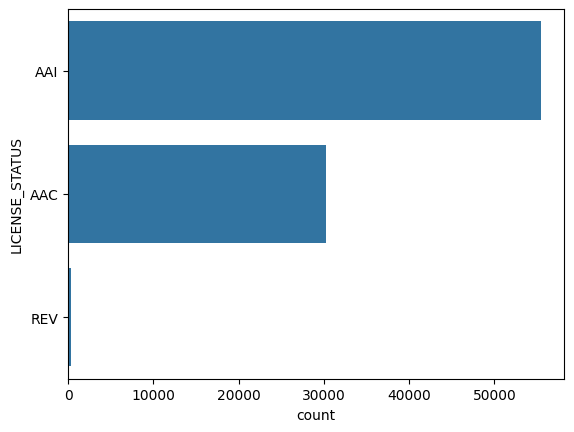

In [34]:
sns.countplot(pdf['LICENSE_STATUS'])
plt.show

In [35]:
pdf.CONDITIONAL_APPROVAL.value_counts()

CONDITIONAL_APPROVAL
N    85872
Y       18
Name: count, dtype: int64